# State diagram — Exploratory maps

Initial characterization of the $N=1000$ campaign in the $(\rho,\widetilde\kappa)$ plane. We compare morphology, global alignment, cell motion, and the extent of polar-aligned clusters.

For now, we use the **provisional late-time window** $1500\leq t\leq2000$. Every observable is averaged **first in time for each realization**, then across the 64 independent realizations. This is an exploratory summary, **not** a claim of full stationarity or a phase-transition boundary.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Work from the repository root or state_diagram/.
cwd = Path.cwd().resolve()
root = cwd if (cwd / "processed").is_dir() else cwd / "state_diagram"
processed = root / "processed"

files = {
    "order": processed / "order_parameters/order_parameters.parquet",
    "motion": processed / "motion/motion.parquet",
    "clusters": processed / "clusters/cluster_time_series.parquet",
}
for name, path in files.items():
    if not path.is_file():
        raise FileNotFoundError(f"Missing {name}: {path}")

rhos = [0.60, 0.75, 0.85, 0.90, 0.98]
kappas = [0.75, 1.50, 2.50, 4.00]
window = (1500.0, 2000.0)
keys = ["rho", "kappa", "seed"]

## Observables and cluster definition

- $f_E$: fraction of elongated cells.
- $P_2=f_EP$ and $Q_2=f_EQ$: polar and nematic order normalized by **all** cells, not only elongated ones.
- $\langle|\mathbf v|\rangle$: mean instantaneous mechanical speed.
- $P_v$: polarization of instantaneous velocities (undefined if all speeds vanish).
- $S_1/N$: fraction of **all** cells in the largest **polar-aligned elongated** cluster, using the original neighbor/contact criterion (`range_factor = 1.0`) and the model's $45^\circ$ polar alignment threshold.

$S_1/N$ depends on the chosen graph rule and on $f_E$. We will compare alternative connectivity definitions only if the initial maps justify doing so.

In [2]:
order = pd.read_parquet(
    files["order"],
    columns=keys + ["time", "fraction_elongated", "polar_2", "nematic_2"],
)
motion = pd.read_parquet(
    files["motion"],
    columns=keys + ["time", "mean_instantaneous_speed", "velocity_polarization"],
)
clusters = pd.read_parquet(
    files["clusters"],
    columns=keys + ["time", "phenotype", "alignment", "range_factor", "S1_over_N", "fraction_phenotype"],
)

clusters = clusters.loc[
    clusters["phenotype"].eq("elongated")
    & clusters["alignment"].eq("polar")
    & np.isclose(clusters["range_factor"], 1.0)
].copy()


def late_time_means(data, observables):
    selected = data.loc[data["time"].between(*window)]
    return selected.groupby(keys, as_index=False)[observables].mean()

per_seed = late_time_means(
    order, ["fraction_elongated", "polar_2", "nematic_2"]
).merge(
    late_time_means(motion, ["mean_instantaneous_speed", "velocity_polarization"]),
    on=keys, validate="one_to_one",
).merge(
    late_time_means(clusters, ["S1_over_N", "fraction_phenotype"]),
    on=keys, validate="one_to_one",
)

# Only a minimal structural check; full file validation is in 00_data_validation.
realizations_per_point = per_seed.groupby(["rho", "kappa"]).size()
assert len(realizations_per_point) == 20 and realizations_per_point.eq(64).all()

means = per_seed.groupby(["rho", "kappa"], as_index=False).mean(numeric_only=True)
print(f"Late-time window: {window[0]:g}–{window[1]:g}")
print("Points:", len(means), " | Realizations:", len(per_seed))

Late-time window: 1500–2000
Points: 20  | Realizations: 1280


## First maps

Each square represents **one simulated point**; no interpolation is applied. The horizontal and vertical positions are categorical in this figure (they do not encode the unequal numerical spacing between sampled parameter values).

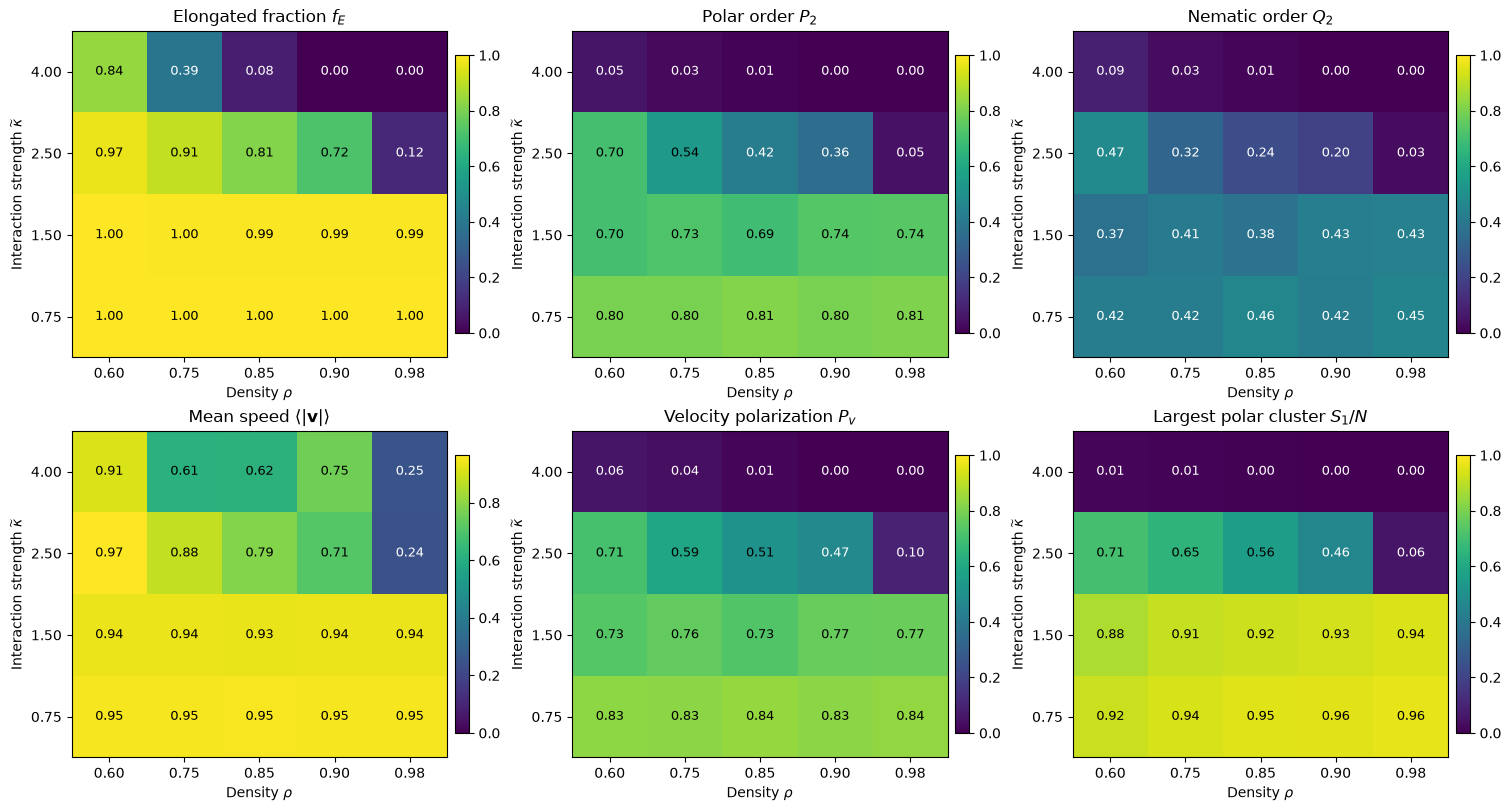

In [3]:
observables = [
    ("fraction_elongated", r"Elongated fraction $f_E$", 1.0),
    ("polar_2", r"Polar order $P_2$", 1.0),
    ("nematic_2", r"Nematic order $Q_2$", 1.0),
    ("mean_instantaneous_speed", r"Mean speed $\langle |\mathbf{v}|\rangle$", None),
    ("velocity_polarization", r"Velocity polarization $P_v$", 1.0),
    ("S1_over_N", r"Largest polar cluster $S_1/N$", 1.0),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
for ax, (column, title, ceiling) in zip(axes.flat, observables):
    matrix = (
        means.pivot(index="kappa", columns="rho", values=column)
        .reindex(index=kappas, columns=rhos)
        .to_numpy(dtype=float)
    )

    im = ax.imshow(
        matrix,
        origin="lower",
        interpolation="nearest",
        aspect="auto",
        cmap="viridis",
        vmin=0,
        vmax=ceiling,
    )
    ax.set_title(title, fontsize=12)
    ax.set_xticks(range(len(rhos)), [f"{v:.2f}" for v in rhos])
    ax.set_yticks(range(len(kappas)), [f"{v:.2f}" for v in kappas])
    ax.set_xlabel(r"Density $\rho$")
    ax.set_ylabel(r"Interaction strength $\widetilde\kappa$")

    # Printed values help to compare discrete states without interpolation.
    norm = im.norm
    for iy in range(len(kappas)):
        for ix in range(len(rhos)):
            value = matrix[iy, ix]
            if np.isfinite(value):
                text_color = "white" if norm(value) < 0.50 else "black"
                ax.text(ix, iy, f"{value:.2f}", ha="center", va="center",
                        color=text_color, fontsize=9)
    fig.colorbar(im, ax=ax, shrink=0.85, pad=0.02)

figure_dir = root / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_dir / "state_diagram_main_maps.png", dpi=200, bbox_inches="tight")
plt.show()

## Conditional cluster extent and between-realization fluctuations

A decrease in $S_1/N$ can simply reflect the loss of elongated cells. To separate this from fragmentation of the *remaining* elongated population, also examine $S_1/N_E$. For each realization, we compute

$$
\frac{\overline{S_1/N}}{\overline{f_E}}=\frac{\overline{S_1}}{\overline{N_E}},
$$

using the same **cluster-output times** in the late-time window for numerator and denominator. This is weighted by $N_E$ across those recorded times, and is **undefined** when no elongated cells remain throughout the window. When reported, it measures the fraction of the available elongated population belonging to the largest polar-aligned cluster, not the fraction of all cells in that cluster.

We also show the **sample variance across the 64 realization-wise time averages**, rather than the variance of individual snapshots. These quantify *between-realization heterogeneity*, not a critical susceptibility or temporal fluctuations within a run.

In [4]:
# Conditional connectivity: both numerator and N_E come from the same cluster snapshots.
per_seed["S1_over_NE"] = per_seed["S1_over_N"].div(
    per_seed["fraction_phenotype"].where(per_seed["fraction_phenotype"] > 0)
)

# A connected cluster of elongated cells cannot exceed the elongated population.
valid = per_seed["S1_over_NE"].dropna()
assert valid.between(0, 1 + 1e-10).all(), "Unexpected S1/N_E normalization"

fluctuations = (
    per_seed.groupby(["rho", "kappa"])[
        ["fraction_elongated", "polar_2", "S1_over_N"]
    ]
    .var(ddof=1)
    .rename(columns={
        "fraction_elongated": "var_fraction_elongated",
        "polar_2": "var_polar_2",
        "S1_over_N": "var_S1_over_N",
    })
    .reset_index()
)
connectivity = (
    per_seed.groupby(["rho", "kappa"], as_index=False)
    .agg(
        S1_over_NE=("S1_over_NE", "mean"),
        valid_seeds=("S1_over_NE", "count"),
    )
)
extra_maps = fluctuations.merge(connectivity, on=["rho", "kappa"], validate="one_to_one")

incomplete = extra_maps.loc[extra_maps["valid_seeds"].lt(64),
                            ["rho", "kappa", "valid_seeds"]]
if not incomplete.empty:
    print("Points with fewer than 64 realizations containing elongated cells:")
    print(incomplete.to_string(index=False))

Points with fewer than 64 realizations containing elongated cells:
 rho  kappa  valid_seeds
0.90    4.0            8
0.98    2.5           24
0.98    4.0            0


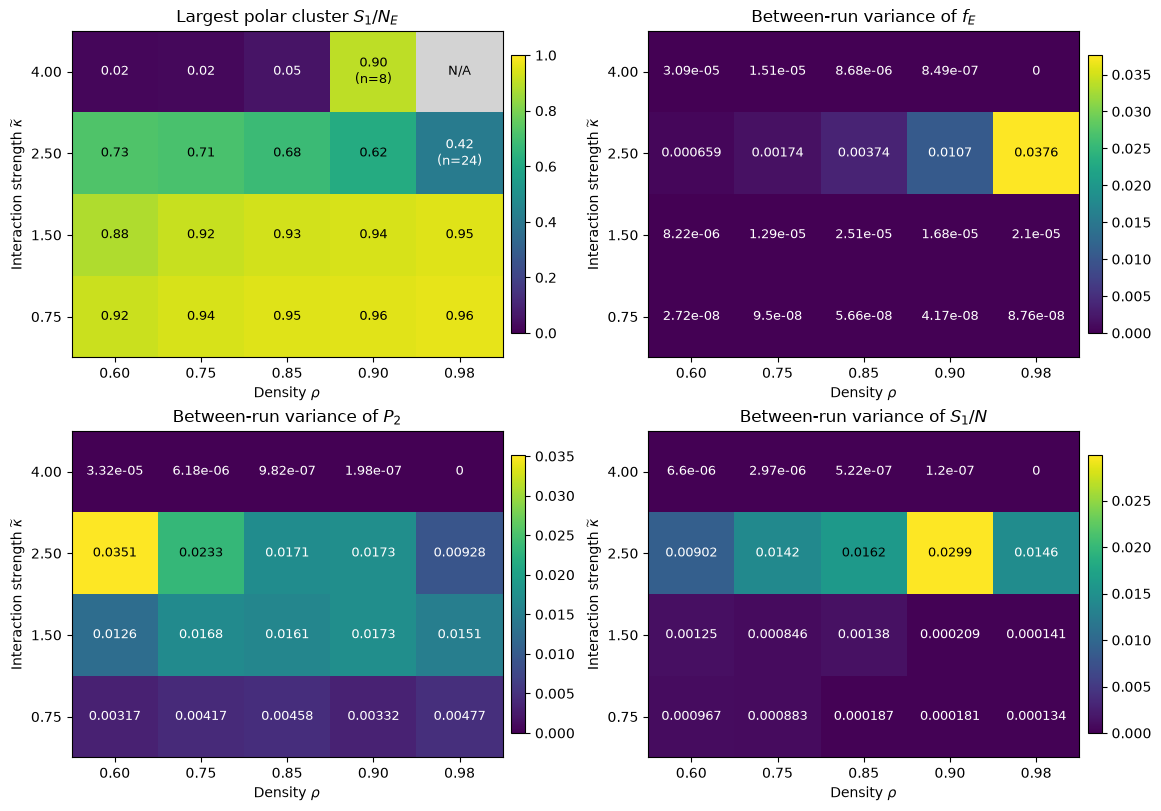

In [5]:
extra_observables = [
    ("S1_over_NE", r"Largest polar cluster $S_1/N_E$", 1.0),
    ("var_fraction_elongated", r"Between-run variance of $f_E$", None),
    ("var_polar_2", r"Between-run variance of $P_2$", None),
    ("var_S1_over_N", r"Between-run variance of $S_1/N$", None),
]

fig, axes = plt.subplots(2, 2, figsize=(11.5, 8), constrained_layout=True)
for ax, (column, title, ceiling) in zip(axes.flat, extra_observables):
    matrix = (
        extra_maps.pivot(index="kappa", columns="rho", values=column)
        .reindex(index=kappas, columns=rhos)
        .to_numpy(dtype=float)
    )
    finite = matrix[np.isfinite(matrix)]
    vmax = ceiling if ceiling is not None else (max(float(finite.max()), 1e-12) if finite.size else 1)
    cmap = plt.get_cmap("viridis").copy()
    cmap.set_bad("lightgray")
    im = ax.imshow(
        np.ma.masked_invalid(matrix), origin="lower", interpolation="nearest",
        aspect="auto", cmap=cmap, vmin=0, vmax=vmax,
    )
    ax.set_title(title)
    ax.set_xticks(range(len(rhos)), [f"{x:.2f}" for x in rhos])
    ax.set_yticks(range(len(kappas)), [f"{x:.2f}" for x in kappas])
    ax.set_xlabel(r"Density $\rho$")
    ax.set_ylabel(r"Interaction strength $\widetilde\kappa$")

    n_matrix = (
        extra_maps.pivot(index="kappa", columns="rho", values="valid_seeds")
        .reindex(index=kappas, columns=rhos)
        .to_numpy(dtype=int)
    )
    for iy in range(len(kappas)):
        for ix in range(len(rhos)):
            value = matrix[iy, ix]
            if not np.isfinite(value):
                label = "N/A"
            elif column == "S1_over_NE":
                label = f"{value:.2f}"
                if n_matrix[iy, ix] < 64:
                    label += f"\n(n={n_matrix[iy, ix]})"
            else:
                label = f"{value:.3g}"
            color = ("white" if np.isfinite(value) and im.norm(value) < 0.5
                     else "black")
            ax.text(ix, iy, label, ha="center", va="center", fontsize=9, color=color)
    fig.colorbar(im, ax=ax, shrink=0.85, pad=0.02)

figure_dir = root / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_dir / "state_diagram_fluctuations.png", dpi=200, bbox_inches="tight")
plt.show()

### Interpretation to revisit after inspecting the maps

The region around $\widetilde\kappa=2.5$ is particularly relevant to the question of whether passive (round) cells alter collective behavior. If $S_1/N$ decreases as $f_E$ decreases but $S_1/N_E$ remains high, much of the change is attributable to fewer elongated cells. If **both** cluster fractions decline, the remaining elongated population is also becoming more fragmented under the selected polar-connectivity rule.

A maximum in between-realization variance would motivate finer parameter sampling, but **would not by itself establish a critical transition**. The late-time interval $1500\le t\le2000$ is provisional, particularly near $(\rho,\widetilde\kappa)=(0.60,2.50)$, where we saw hints of slow relaxation. We will decide whether to test window sensitivity after inspecting these results, rather than adding further plots by default.

## Between-realization distributions at $\widetilde\kappa=2.5$

The variance maps suggest substantial heterogeneity at intermediate interaction strength, especially near $\rho=0.90$–$0.98$. Here we examine the **64 realization-wise late-time averages** rather than individual snapshots: the distributions of $f_E$ and $S_1/N$, and their relationship within each run. This helps distinguish a broad continuous spread from distinct groups of outcomes. No statistical phase classification is assumed.

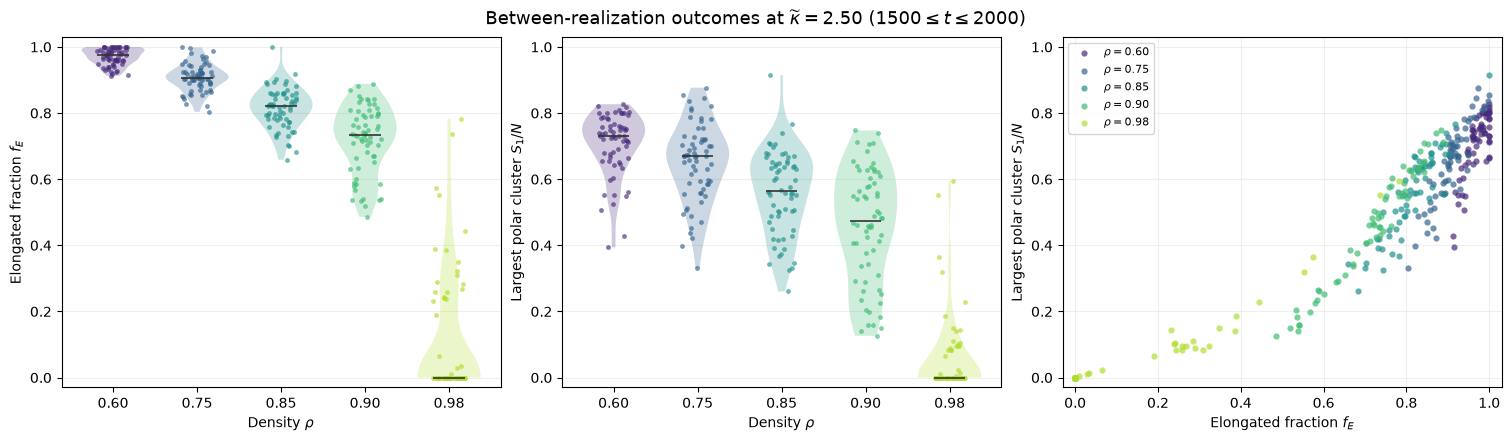

In [6]:
# One figure: marginal distributions and paired outcomes, at fixed kappa.
selected_kappa = 2.50
subset = per_seed.loc[np.isclose(per_seed["kappa"], selected_kappa)].copy()
assert subset.groupby("rho").size().reindex(rhos).eq(64).all()

colors = plt.get_cmap("viridis")(np.linspace(0.12, 0.88, len(rhos)))
rng = np.random.default_rng(2026)  # Visual jitter only; data are unchanged.

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), constrained_layout=True)

for ax, (column, label) in zip(
    axes[:2],
    [("fraction_elongated", r"Elongated fraction $f_E$"),
     ("S1_over_N", r"Largest polar cluster $S_1/N$")],
):
    samples = [subset.loc[np.isclose(subset["rho"], rho), column].dropna().to_numpy()
               for rho in rhos]
    violins = ax.violinplot(
        samples, positions=np.arange(len(rhos)), widths=0.75,
        showmeans=False, showmedians=True, showextrema=False,
    )
    for body, color in zip(violins["bodies"], colors):
        body.set_facecolor(color)
        body.set_edgecolor("none")
        body.set_alpha(0.25)
    violins["cmedians"].set_color("0.2")
    violins["cmedians"].set_linewidth(1.2)

    # Show actual run values so that possible multimodality is not hidden by smoothing.
    for i, (values, color) in enumerate(zip(samples, colors)):
        x = i + rng.uniform(-0.19, 0.19, size=len(values))
        ax.scatter(x, values, s=12, color=color, alpha=0.65, linewidths=0)

    ax.set_xticks(np.arange(len(rhos)), [f"{rho:.2f}" for rho in rhos])
    ax.set_xlabel(r"Density $\rho$")
    ax.set_ylabel(label)
    ax.set_ylim(-0.03, 1.03)
    ax.grid(axis="y", alpha=0.20)
    ax.set_axisbelow(True)

# Pair the two measurements by seed, rather than comparing their marginal means.
for rho, color in zip(rhos, colors):
    group = subset.loc[np.isclose(subset["rho"], rho)]
    axes[2].scatter(
        group["fraction_elongated"], group["S1_over_N"],
        s=20, alpha=0.70, color=color, linewidths=0,
        label=rf"$\rho={rho:.2f}$",
    )
axes[2].set_xlabel(r"Elongated fraction $f_E$")
axes[2].set_ylabel(r"Largest polar cluster $S_1/N$")
axes[2].set_xlim(-0.03, 1.03)
axes[2].set_ylim(-0.03, 1.03)
axes[2].grid(alpha=0.20)
axes[2].set_axisbelow(True)
axes[2].legend(loc="upper left", fontsize=8, frameon=True)

fig.suptitle(r"Between-realization outcomes at $\widetilde\kappa=2.50$ ($1500\leq t\leq2000$)", fontsize=13)
figure_dir = root / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_dir / "state_diagram_distributions.png", dpi=200, bbox_inches="tight")
plt.show()

Each point represents **one independent realization averaged over the late-time window**. The violins are visual density estimates, while the dots show the actual observations; apparent multimodality should be assessed from the dots, not the violin shape alone. The right panel relates morphology and cluster extent within each realization, but association alone does not establish a causal effect of round cells. In particular, $S_1/N$ necessarily tends to shrink when fewer elongated cells exist.

## Individual morphology trajectories near $\widetilde\kappa=2.5$

The distributions at $\rho=0.98$ mix runs with nearly zero and appreciable late-time elongation. To check whether these outcomes are still evolving, compare all 64 trajectories at $\rho=0.85$, $0.90$, and $0.98$ (a mostly elongated reference, the largest cluster-variance point, and the most heterogeneous morphological point).

Curves are colored **by their outcome at $T=2000$**, not by a presumed phase: gray if $f_E(T)=0$, blue otherwise. The black line is the mean over all runs. We also compare each run's mean $f_E$ in $1000\le t<1500$ and $1500\le t\le2000$; a small difference is evidence against a large *late-time drift*, not proof of stationarity or bistability.

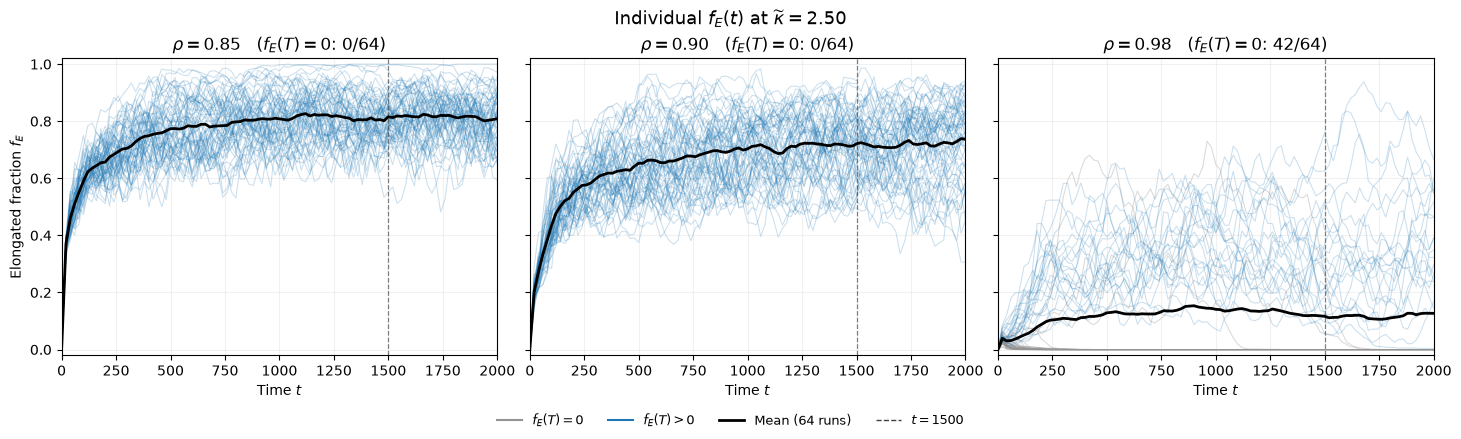

Late-time drift: mean f_E[1500, 2000] minus mean f_E[1000, 1500), per run


,rho,final_zero_runs,mean_delta_fE,median_abs_delta_fE
0,0.85,0,0.0021,0.0396
1,0.90,0,0.0081,0.0675
2,0.98,42,-0.0153,0.0000


In [7]:
from matplotlib.lines import Line2D

selected_kappa = 2.50
selected_rhos = [0.85, 0.90, 0.98]
previous_window = (1000.0, 1500.0)

fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.3), sharex=True, sharey=True,
                         constrained_layout=True)
summary_rows = []

for ax, rho in zip(axes, selected_rhos):
    group = order.loc[
        np.isclose(order["kappa"], selected_kappa)
        & np.isclose(order["rho"], rho)
    ]
    trajectories = (group.pivot(index="time", columns="seed",
                                values="fraction_elongated")
                    .sort_index())
    assert trajectories.shape == (101, 64), f"Unexpected trajectory shape at rho={rho}"
    assert np.isclose(trajectories.index[-1], 2000.0)

    last_values = trajectories.iloc[-1]
    ends_round = last_values.eq(0.0)  # f_E is a cell-count fraction, so zero is exact.

    # Draw individual runs in two groups defined only by the final snapshot.
    for seed in last_values.index[ends_round]:
        ax.plot(trajectories.index, trajectories[seed],
                color="0.58", lw=0.75, alpha=0.35, zorder=1)
    for seed in last_values.index[~ends_round]:
        ax.plot(trajectories.index, trajectories[seed],
                color="tab:blue", lw=0.75, alpha=0.23, zorder=2)
    ax.plot(trajectories.index, trajectories.mean(axis=1),
            color="black", lw=2.0, zorder=3)

    ax.axvline(window[0], color="0.25", ls="--", lw=0.9, alpha=0.65)
    ax.set_title(rf"$\rho={rho:.2f}$   ($f_E(T)=0$: {int(ends_round.sum())}/64)")
    ax.set_xlabel(r"Time $t$")
    ax.set_xlim(0, 2000)
    ax.set_ylim(-0.02, 1.02)
    ax.grid(alpha=0.17)

    earlier = trajectories.loc[
        (trajectories.index >= previous_window[0])
        & (trajectories.index < previous_window[1])
    ].mean(axis=0)
    later = trajectories.loc[trajectories.index >= window[0]].mean(axis=0)
    delta = later - earlier
    summary_rows.append({
        "rho": rho,
        "final_zero_runs": int(ends_round.sum()),
        "mean_delta_fE": float(delta.mean()),
        "median_abs_delta_fE": float(delta.abs().median()),
    })

axes[0].set_ylabel(r"Elongated fraction $f_E$")
legend_handles = [
    Line2D([], [], color="0.58", lw=1.5, label=r"$f_E(T)=0$"),
    Line2D([], [], color="tab:blue", lw=1.5, label=r"$f_E(T)>0$"),
    Line2D([], [], color="black", lw=2, label="Mean (64 runs)"),
    Line2D([], [], color="0.25", ls="--", lw=1, label=r"$t=1500$"),
]
fig.legend(handles=legend_handles, loc="outside lower center", ncol=4,
           frameon=False, fontsize=9)
fig.suptitle(r"Individual $f_E(t)$ at $\widetilde\kappa=2.50$", fontsize=13)
figure_dir = root / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_dir / "state_diagram_individual_trajectories.png", dpi=200, bbox_inches="tight")
plt.show()

print("Late-time drift: mean f_E[1500, 2000] minus mean f_E[1000, 1500), per run")
display(pd.DataFrame(summary_rows).round(4))


The numbers of fully round runs refer to the **final snapshot** and need not equal the number of runs contributing to a conditional $S_1/N_E$ average over the whole late-time window. Persistently distinct trajectories would motivate longer simulations and a window-sensitivity check before interpreting the between-run variance as evidence of coexistence.

## Possible trapping in the all-round state

The $f_E(T)=0$ outcomes at $(\rho,\widetilde\kappa)=(0.98,2.5)$ suggest that the all-round configuration may become **effectively absorbing after the initial transient**. However, $f_E=0$ is not absorbing by construction: all cells are initially round and can elongate, and round cells continue to attempt elongation during the dynamics. Successful reactivation can therefore depend on the available space and the mechanical configuration.

As a minimal check, count whether any realization that **returned to $f_E=0$ after being elongated** subsequently recovered a nonzero $f_E$ in the **recorded snapshots**. This cannot rule out brief reactivations between snapshots (saved every 20 time units), or prove infinite-time absorption.

In [8]:
# Observed zero-state returns and subsequent reactivations at kappa = 2.5.
# Ignore the initially all-round state at t = 0.
focus_rhos = [0.85, 0.90, 0.98]
subset = order.loc[
    np.isclose(order["kappa"], 2.5)
    & order["rho"].isin(focus_rhos)
    & (order["time"] > 0),
    ["rho", "seed", "time", "fraction_elongated"],
].sort_values(["rho", "seed", "time"])

records = []
for (rho, seed), group in subset.groupby(["rho", "seed"]):
    f = group["fraction_elongated"].to_numpy()
    previously_elongated = np.maximum.accumulate(f > 0)
    returns = np.flatnonzero((f == 0) & previously_elongated)
    returned = len(returns) > 0
    revived = bool(returned and np.any(f[returns[0] + 1:] > 0))
    records.append({"rho": rho, "returned_to_zero": returned, "reactivated": revived})

zero_events = pd.DataFrame(records)
summary = zero_events.groupby("rho")[["returned_to_zero", "reactivated"]].sum()
display(summary.reindex(focus_rhos, fill_value=0).astype(int))

,returned_to_zero,reactivated
rho,,
0.85,0,0
0.90,0,0
0.98,42,0


## Discussion and scope

At weak interactions, the model exhibits a predominantly elongated population with strong polar alignment, coherent motion, and large connected polar clusters. At $\widetilde\kappa=2.5$, increasing density reduces $f_E$, global polar order, velocity polarization, and the extent of the largest polar cluster. The decrease in $S_1/N_E$ indicates that the remaining elongated cells also become less connected under the selected cluster definition; this is not explained solely by having fewer elongated cells.

Between-realization fluctuations of $S_1/N$ are largest near $\rho=0.90$ on the sampled $\widetilde\kappa=2.5$ row. At $\rho=0.98$, **42 of 64 realizations have $f_E(T)=0$**, while others retain elongated cells. The all-round state is a candidate for *effective long-lived trapping*, but the present trajectories and sampling do not establish an absorbing phase, bistability, or a true phase transition. Nor do they establish that round cells are the causal mechanism behind the loss of collective organization.

These results motivate **targeted refinement of the density–interaction grid**, followed by longer runs in potentially slow-relaxing regions and selected larger system sizes. A detailed critical-point study is premature until a candidate transition and a suitable order parameter are better established.